C:\Users\mindi\Meu Drive\UMinho\Doutorado\LUNA\src\luna_xai\utils\metrics.py:166: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, _ = spearmanr(x, values)


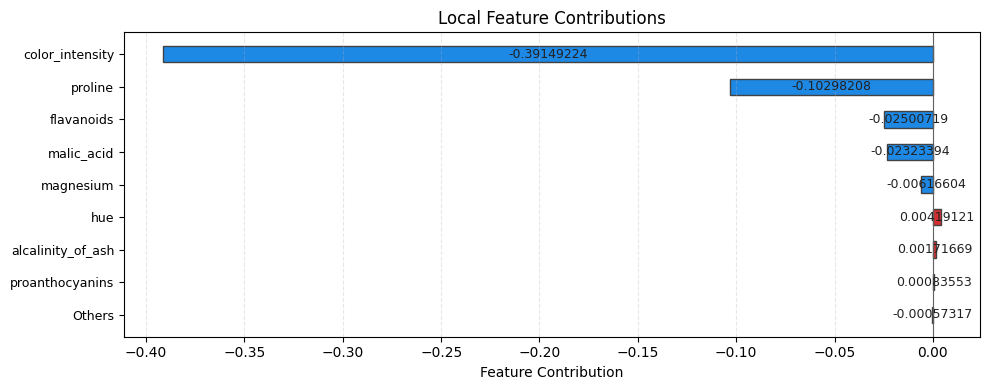

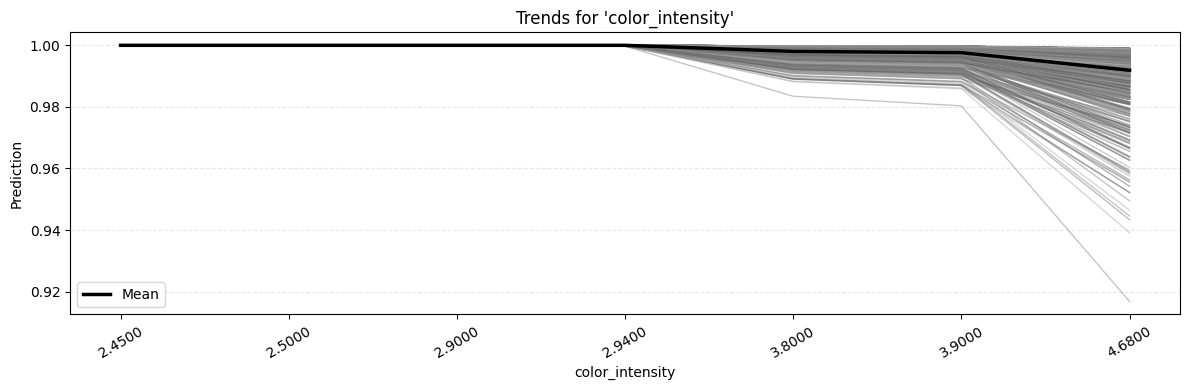

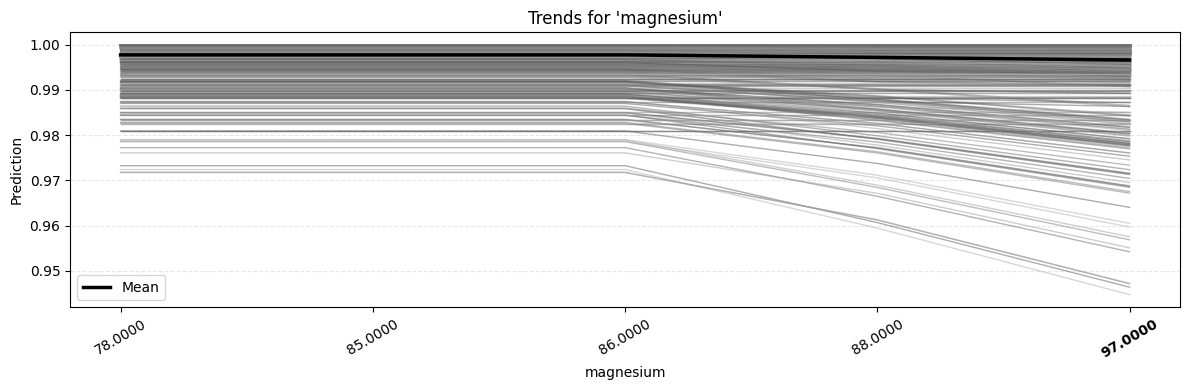

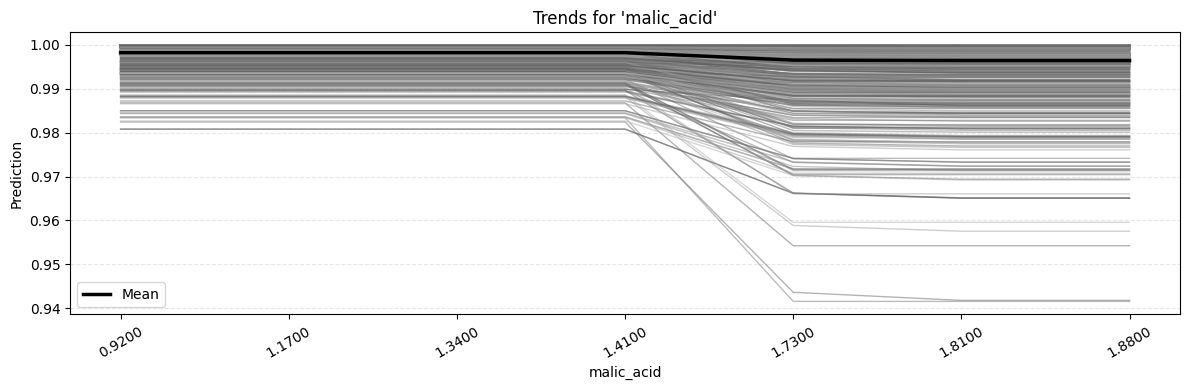

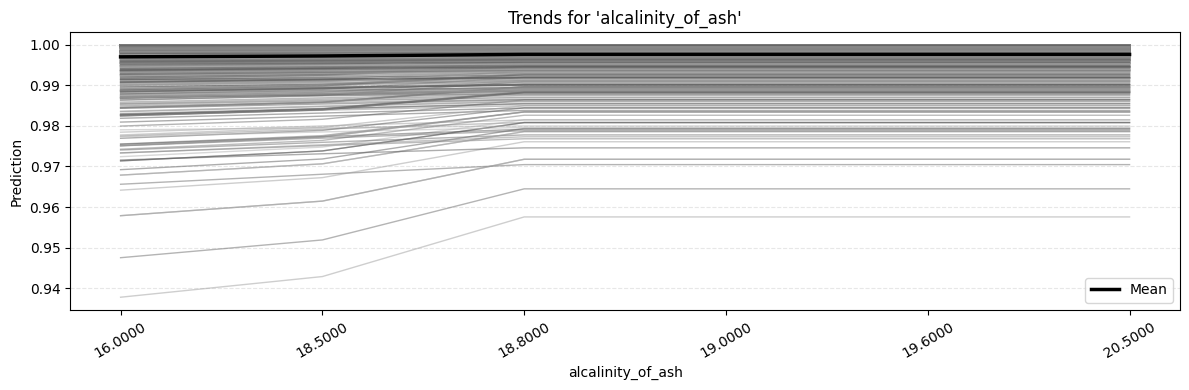

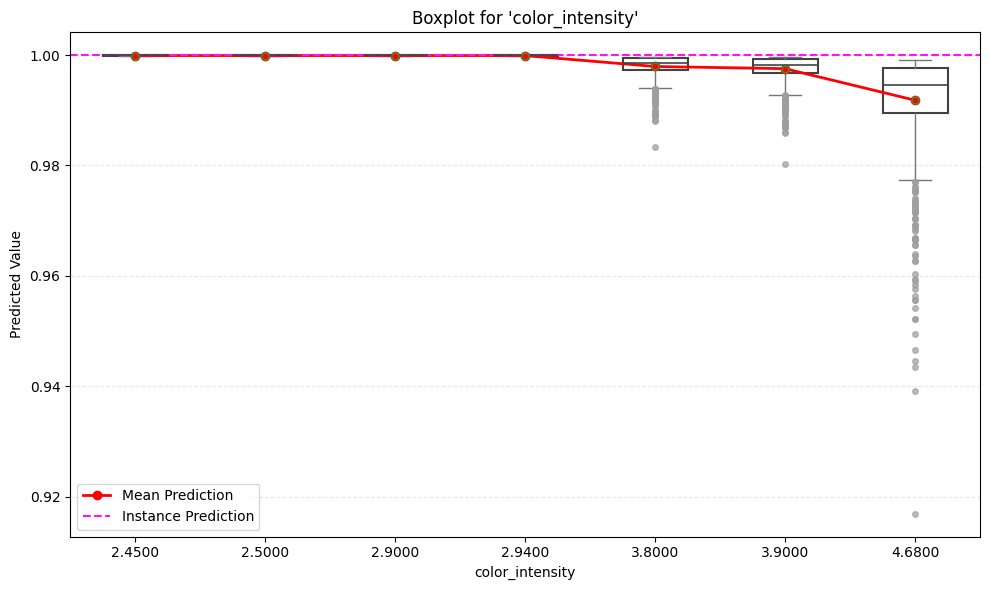

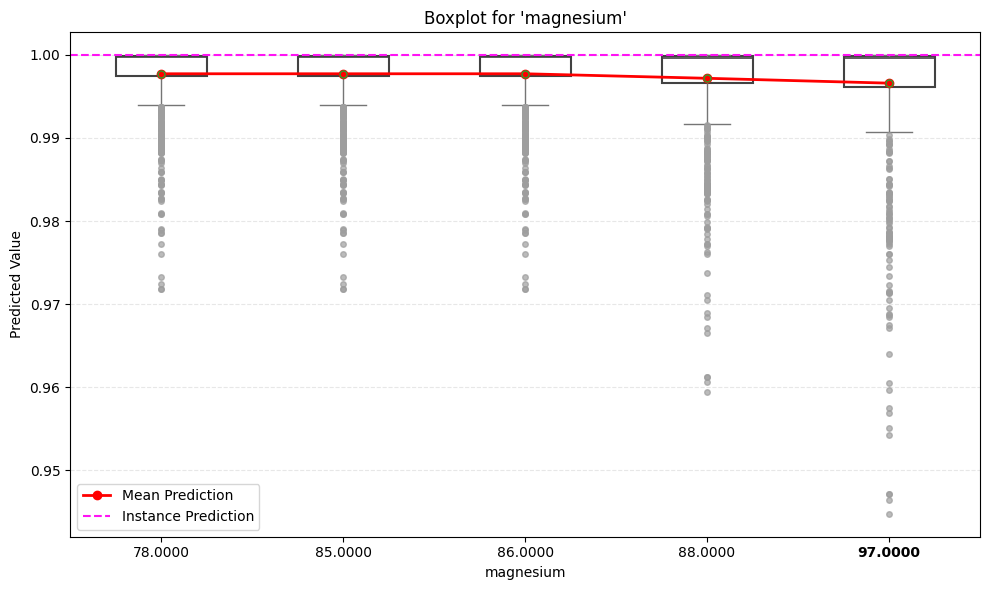

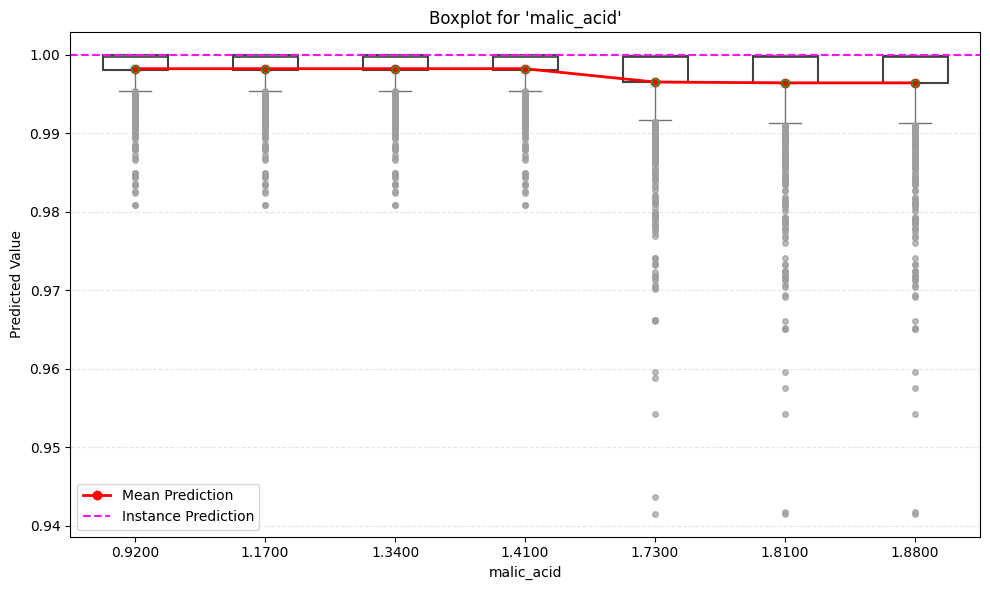

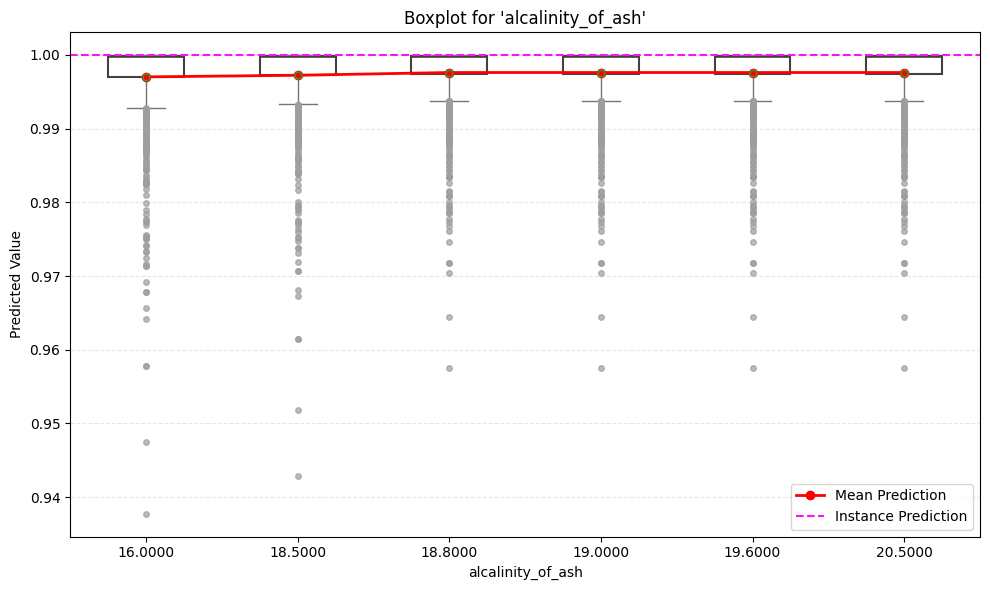

C:\Users\mindi\Meu Drive\UMinho\Doutorado\LUNA\src\luna_xai\utils\metrics.py:166: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, _ = spearmanr(x, values)


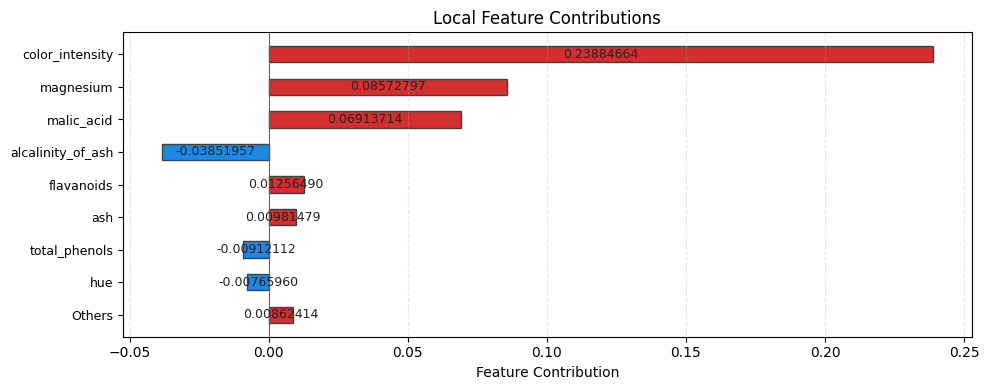

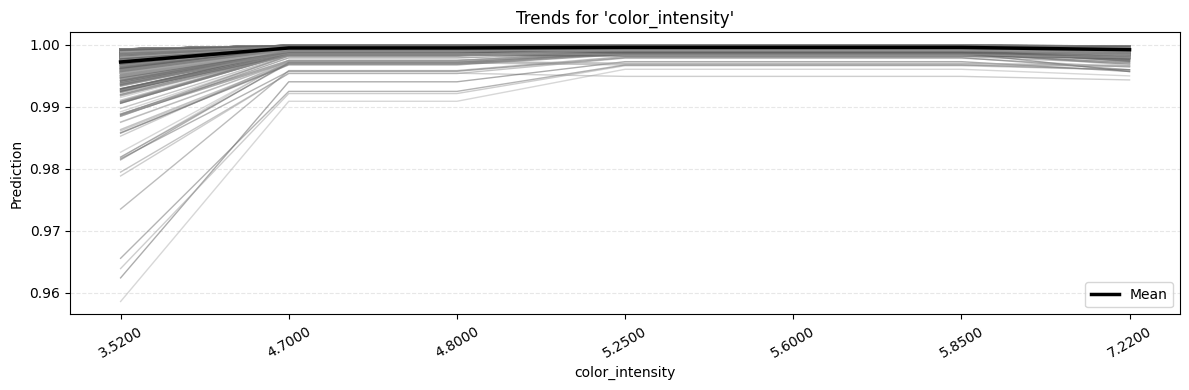

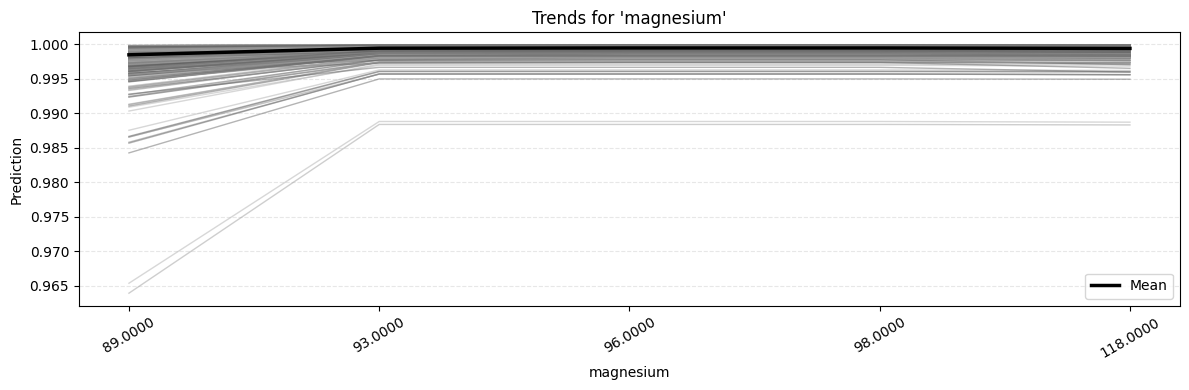

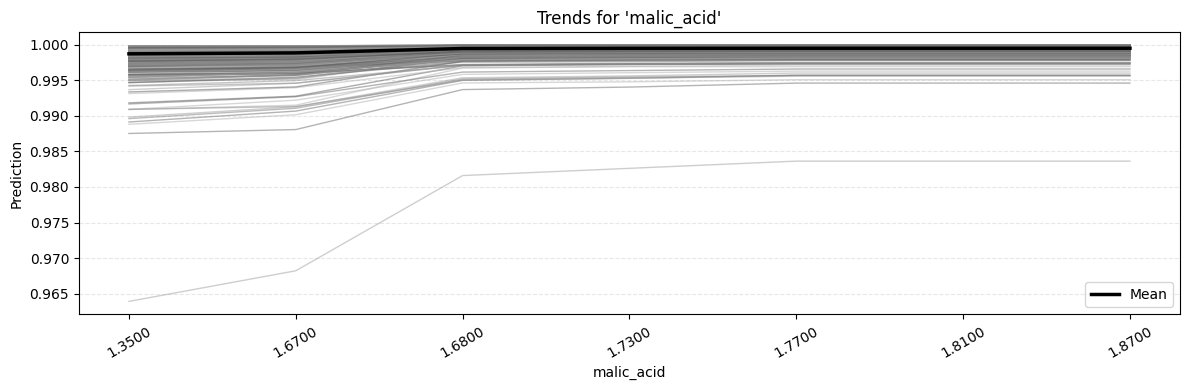

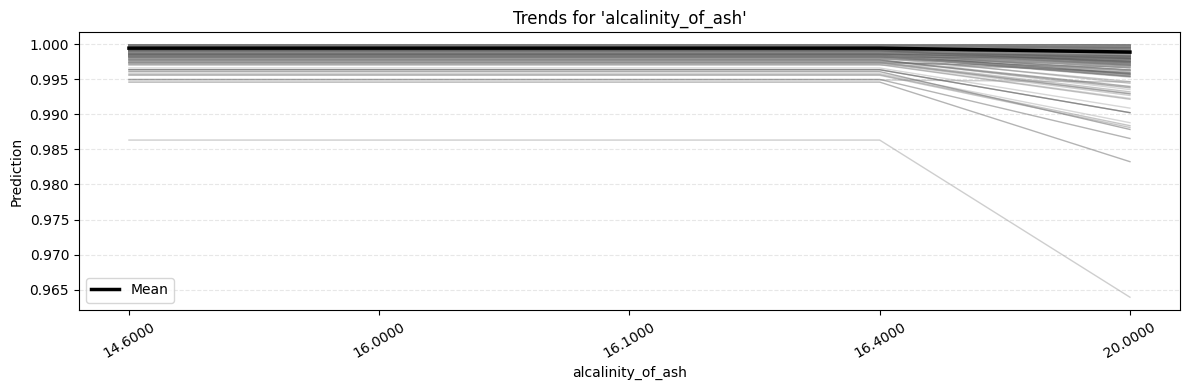

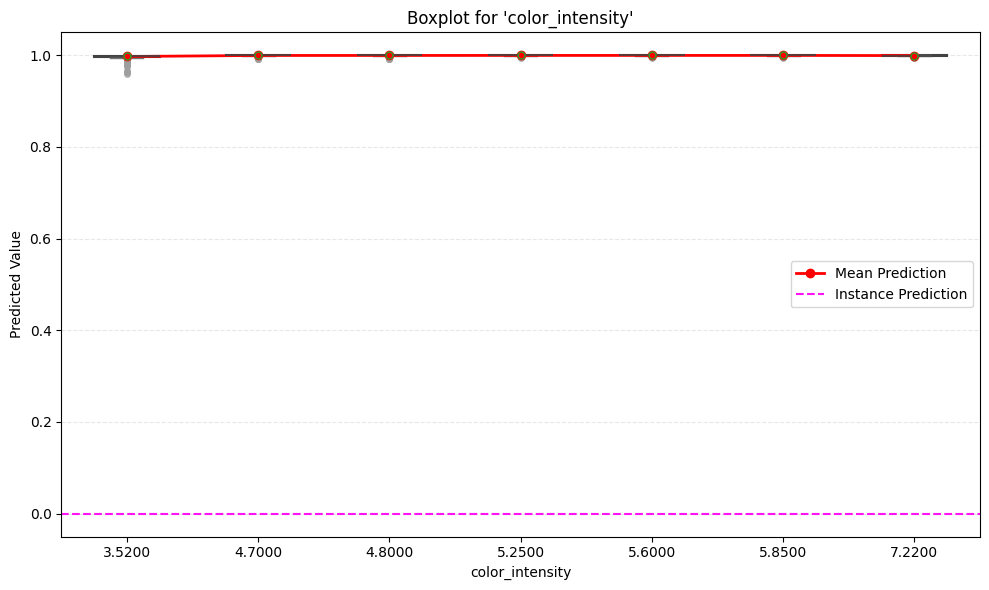

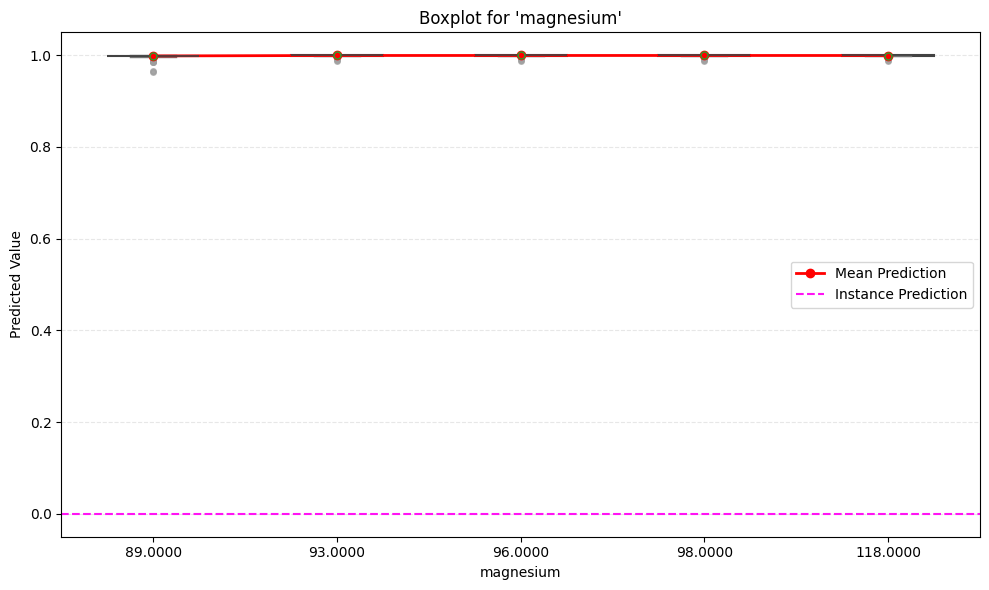

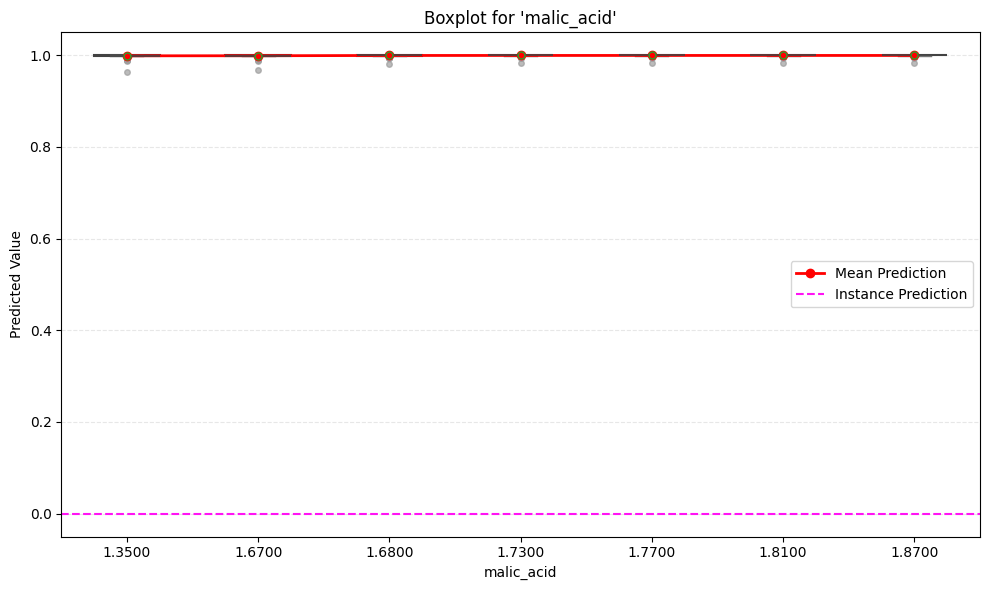

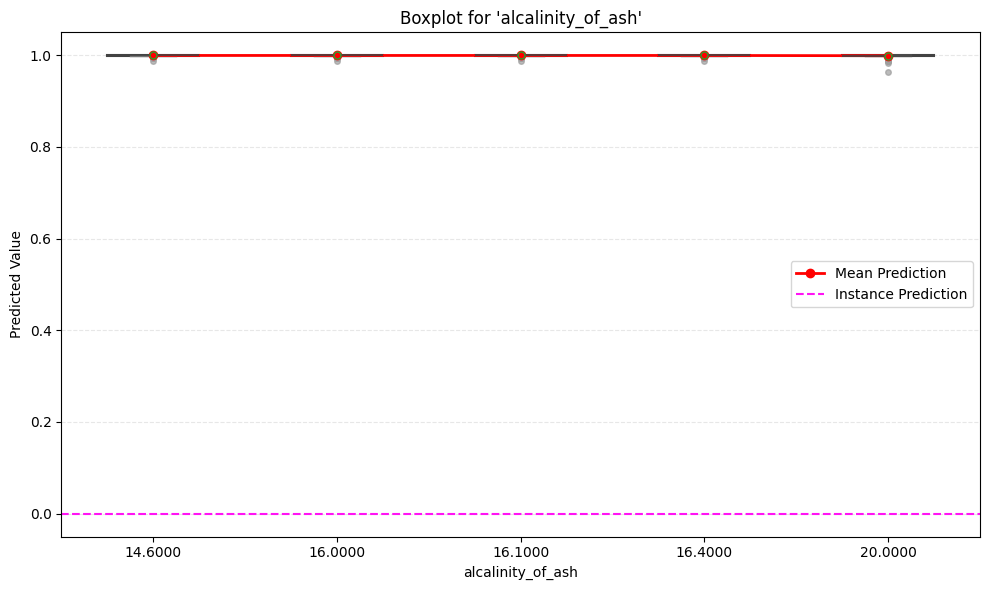

C:\Users\mindi\Meu Drive\UMinho\Doutorado\LUNA\src\luna_xai\utils\metrics.py:166: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, _ = spearmanr(x, values)


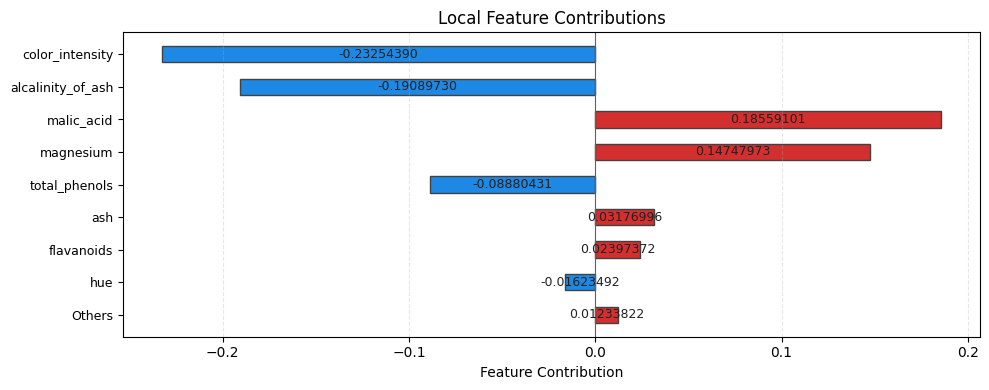

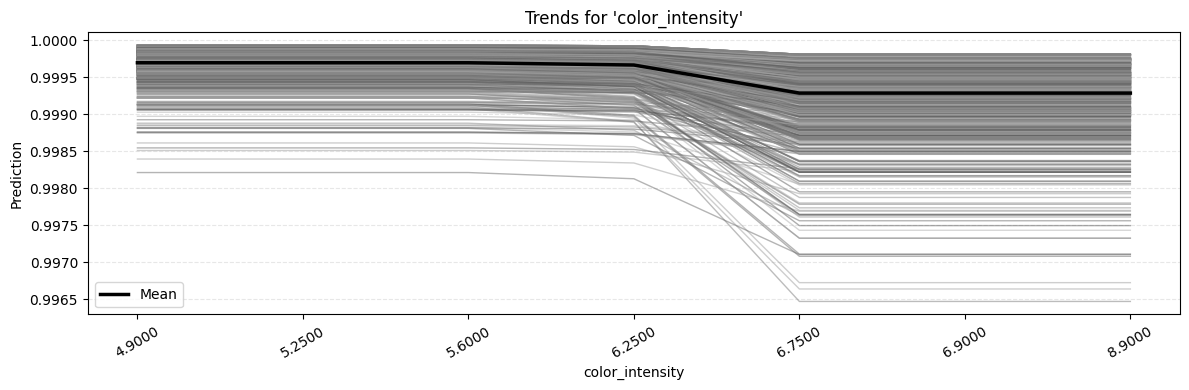

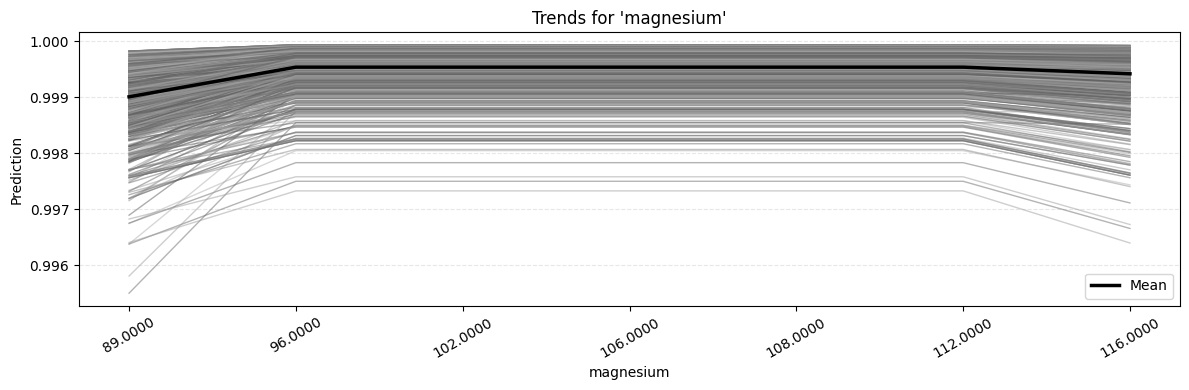

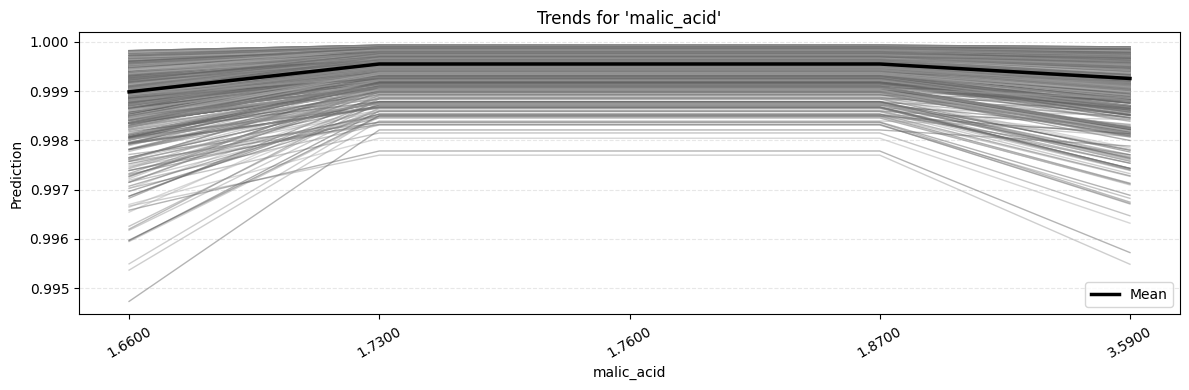

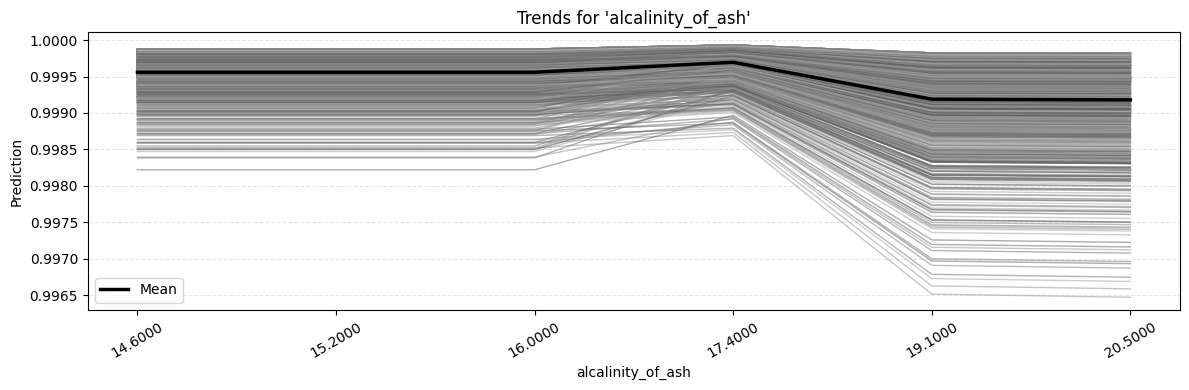

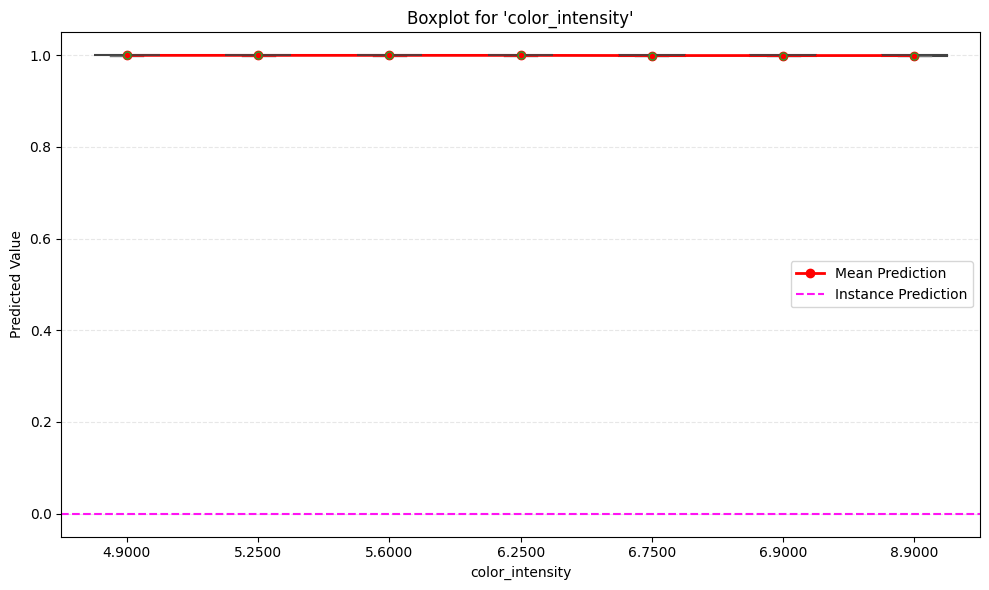

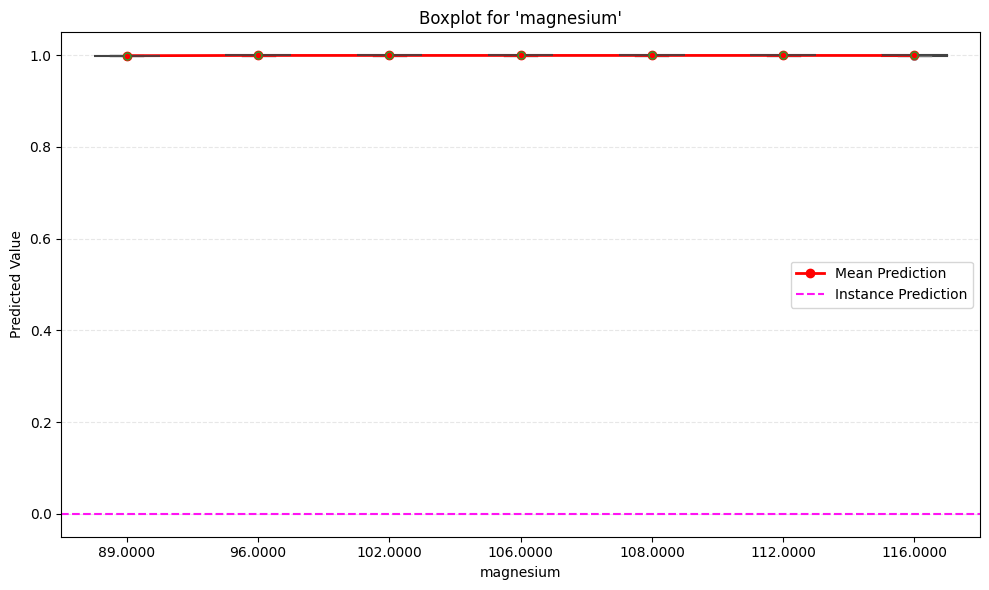

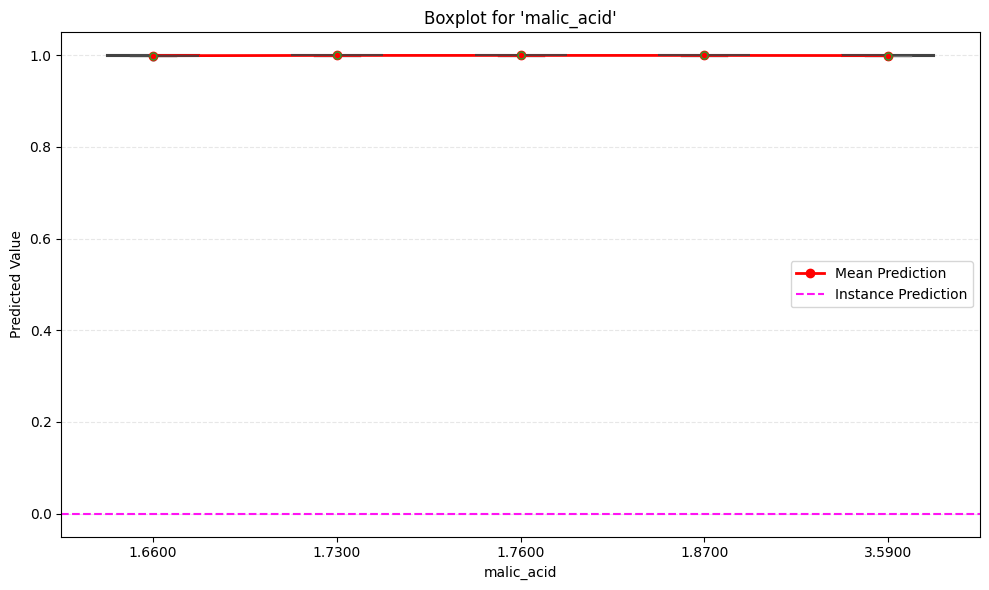

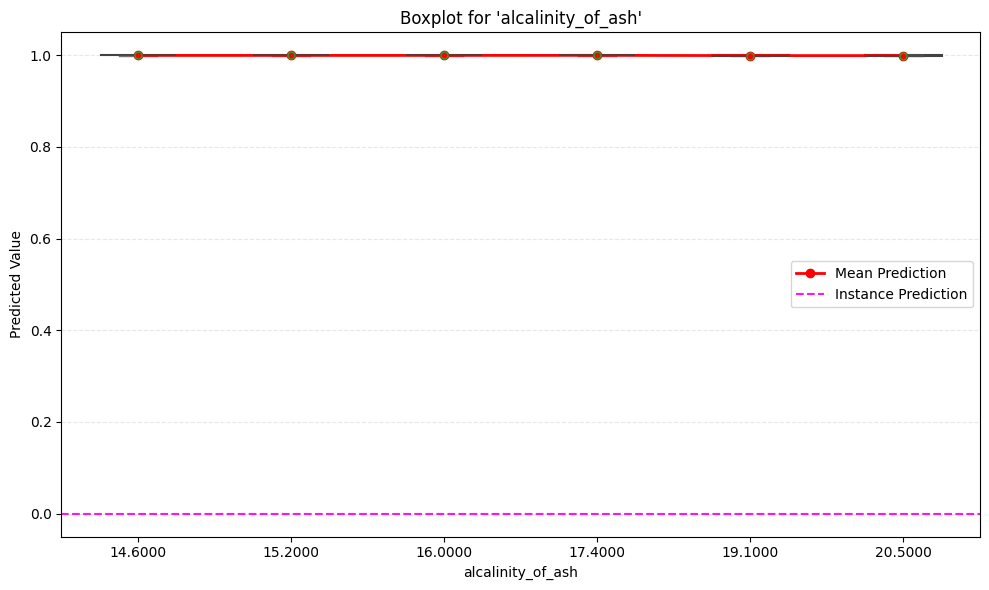

In [ ]:
import pandas as pd
import numpy as np

from sklearn.datasets import load_wine
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split

from pathlib import Path

from luna_xai.utils import (
    ensure_directory,
)
from luna_xai.utils.normalization import arctan_normalize
from luna_xai.domains.tabular_domain_manager import TabularDomainManager
from luna_xai.data import DataInterface

from luna_xai.methods.dsa_method import DSAMethod
from luna_xai.metrics.ch_metric import CHMetric
from luna_xai.renderers.plot_renderer import PlotRenderer
from luna_xai.core.plot_exporter import MatplotlibPngExporter
from luna_xai.explainers.tabular_classification import TabularClassificationExplainer

# ---------------------------------------------------------------------
# ⚙️ Paths and setup of data and model
# ---------------------------------------------------------------------

# Load data
X, y = load_wine(return_X_y=True, as_frame=True)

NUMERIC = X.columns.tolist()

# Feature pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC),
    ]
)


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

# Prepare data
X_train_p = preprocessor.fit_transform(X_train)

model = HistGradientBoostingClassifier(
    max_depth=4,
    learning_rate=0.05,
    max_iter=300,
    min_samples_leaf=15,
    l2_regularization=0.5,
    random_state=42
)

model.fit(X_train_p, y_train)

# ---------------------------------------------------------------------
# ⚙️ Paths and setup of LUNA
# ---------------------------------------------------------------------
from pathlib import Path

BASE_DIR = Path.cwd()
SAVE_DIR = BASE_DIR / "saved_domain_classification"
FILES_DIR = BASE_DIR / "files"
RESULTS_DIR = BASE_DIR / "results_classification"
RANDONM_SEED = 42  # Optional

ensure_directory(RESULTS_DIR)

# ---------------------------------------------------------------------
# 📜 LUNA Domain creation
#     Perform this step only after training the model.
#     This step only needs to be performed once for each trained model. 
#     During domain creation, all the infrastructure and information 
#     required to generate explanations are persisted, allowing the domain 
#     to be reused whenever new instances need to be explained. 
#     **The domain only needs to be recreated if the underlying model is retrained.**
# ---------------------------------------------------------------------

TabularDomainManager.create_and_save(
    model=model,
    pipeline_data=preprocessor,
    pipeline_label=None,
    X_train=X_train,
    categorical_features=None,
    save_dir=SAVE_DIR,
    use_cane=False, # True Only if there are categorical features in the model
    space="l2",
)

# ---------------------------------------------------------------------
# 🧱 LUNA Load persisted domain
#     Perform this step whenever you generate an explanation.
#     Once the domain has been created, it can be reused to generate 
#     explanations for new instances, provided the underlying model 
#     has not been retrained. **This step should be performed each time 
#     new explanations are generated**, using the previously saved domain 
#     without rebuilding it.
# ---------------------------------------------------------------------
domain = TabularDomainManager.load(
    save_dir=SAVE_DIR,
    model=model,
    pipeline_data=preprocessor,
    pipeline_label=None,
    categorical_features=None,
    output_dir=str(RESULTS_DIR),
 ) 

# DataInterface is already within the domain, but I will leave the explicit reference.
data_interface: DataInterface = domain.data_interface

# ---------------------------------------------------------------------
# 🧠 LUNA Build method, metric, renderer, explainer
# ---------------------------------------------------------------------
method = DSAMethod()
method.domain = domain
method.neighbor_finder = domain.get_neighbor_finder()

metric = CHMetric()

# -----------------------------------------------
# Choose one of the graphic exporters
# MatplotlibPdfExporter
# MatplotlibPngExporter
# MatplotlibEpsExporter
# MatplotlibShowExporter
# CompositePlotExporter
# -----------------------------------------------

renderer = PlotRenderer(
    output_dir=str(RESULTS_DIR),
    exporter=MatplotlibPngExporter(),
    features=["color_intensity","magnesium","malic_acid","alcalinity_of_ash"],
    top_k_importances=8,
    show=True,
)

explainer = TabularClassificationExplainer(
    model=model,
    domain=domain,
    method=method,
    metric=metric,
    renderer=renderer,
    output_dir=str(RESULTS_DIR),
    normalizer=arctan_normalize,
)

# ---------------------------------------------------------------------
# 🎯 LUNA Instances to explain
# ---------------------------------------------------------------------
instance_indices = [32, 17, 26]

for idx in instance_indices:

    instance = X_test.iloc[idx]

    # Full explanation (generates importances + calls renderer for local importance)
    result = explainer.explain_instance(instance, idx=str(idx), seed=RANDONM_SEED)

    # Sensitivity data available for additional charts
    sensitivity_data = result.sensitivity_data

    if sensitivity_data:

        # Original prediction of the instance
        original_prediction = float(domain.predict(instance.to_frame().T)[0])

        # 1) Line plots (ICE-like)
        renderer.plot_type = "line"
        renderer.render_from_data(
            sensitivity_data=sensitivity_data,
            plot_type="line",
            instance=instance,
            idx=str(idx),
            instance_prediction=None,  # not used in lineplot
        )

        # 2) Boxplots
        renderer.plot_type = "boxplot"
        renderer.render_from_data(
            sensitivity_data=sensitivity_data,
            plot_type="boxplot",
            instance=instance,
            idx=str(idx),
            instance_prediction=original_prediction,
        )
